# Financial Analysis: Microsoft, Tesla, and Apple
## Task 1: Data Analysis and Insights for AI Chatbot

**Project Goal:** Extract and analyze financial data from 10-K filings to understand corporate financial performance and identify trends.

**Companies Analyzed:**
- Microsoft Corporation (Tech/Software)
- Tesla Inc. (Automotive/Energy)
- Apple Inc. (Consumer Electronics)

**Analysis Period:** 3 fiscal years (2023-2025)

**Key Metrics:**
1. Total Revenue
2. Net Income
3. Total Assets
4. Total Liabilities
5. Operating Cash Flow

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Set up visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

## 1. Data Collection

### Methodology:
- **Source:** SEC EDGAR Database (10-K Filings)
- **Extraction Method:** Manual extraction from consolidated financial statements
- **Key Sections Used:**
  - Item 8: Financial Statements and Supplementary Data
  - Consolidated Income Statements
  - Consolidated Balance Sheets
  - Consolidated Cash Flow Statements
- **Units:** All figures in millions USD

In [13]:
# Financial Data for 3 Companies across 3 Years
data = {
    'Company': [
        'Microsoft', 'Microsoft', 'Microsoft',
        'Tesla', 'Tesla', 'Tesla',
        'Apple', 'Apple', 'Apple'
    ],
    'Year': [2025, 2024, 2023, 2025, 2024, 2023, 2025, 2024, 2023],
    'Total Revenue': [
        281724, 245122, 211915,
        94827, 97690, 96773,
        416161, 391035, 383285
    ],
    'Net Income': [
        101832, 88136, 72361,
        3855, 7153, 14974,
        112010, 93736, 96995
    ],
    'Total Assets': [
        619003, 512163, 411975,
        137806, 122070, 82338,
        359241, 364980, 352583
    ],
    'Total Liabilities': [
        275524, 243686, 205753,
        54941, 48390, 36440,
        285508, 308030, 290437
    ],
    'Operating Cash Flow': [
        136162, 118548, 87582,
        14747, 14923, 13256,
        111482, 118254, 110543
    ]
}

df = pd.DataFrame(data)
print('Dataset Shape:', df.shape)
print('\nFirst Few Rows:')
display(df.head(9))

Dataset Shape: (9, 7)

First Few Rows:


,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Operating Cash Flow
0,Microsoft,2025,281724,101832,619003,275524,136162
1,Microsoft,2024,245122,88136,512163,243686,118548
2,Microsoft,2023,211915,72361,411975,205753,87582
3,Tesla,2025,94827,3855,137806,54941,14747
4,Tesla,2024,97690,7153,122070,48390,14923
5,Tesla,2023,96773,14974,82338,36440,13256
6,Apple,2025,416161,112010,359241,285508,111482
7,Apple,2024,391035,93736,364980,308030,118254
8,Apple,2023,383285,96995,352583,290437,110543


In [14]:
print('=== DATA OVERVIEW ===')
print(f'\nTotal Records: {len(df)}')
print(f'Companies: {df["Company"].nunique()} - {df["Company"].unique().tolist()}')
print(f'Years: {sorted(df["Year"].unique())}')
print(f'\nColumns: {df.columns.tolist()}')
print(f'\nData Types:\n{df.dtypes}')

=== DATA OVERVIEW ===

Total Records: 9
Companies: 3 - ['Microsoft', 'Tesla', 'Apple']
Years: [np.int64(2023), np.int64(2024), np.int64(2025)]

Columns: ['Company', 'Year', 'Total Revenue', 'Net Income', 'Total Assets', 'Total Liabilities', 'Operating Cash Flow']

Data Types:
Company                object
Year                    int64
Total Revenue           int64
Net Income              int64
Total Assets            int64
Total Liabilities       int64
Operating Cash Flow     int64
dtype: object


## 2. Trend Analysis

### Year-over-Year Growth Calculation
We calculate YoY growth rates to understand how each company's financial metrics are changing over time.

In [15]:
# Calculate Year-over-Year Growth Rates
print('=== YEAR-OVER-YEAR GROWTH RATE (%) ===')
print('\nFormula: ((Value_Current_Year - Value_Previous_Year) / Value_Previous_Year) × 100\n')

for company in ['Microsoft', 'Tesla', 'Apple']:
    print(f'\n{company}:')
    print('-' * 60)
    company_data = df[df['Company'] == company].sort_values('Year', ascending=False).reset_index(drop=True)

    # Revenue Growth
    if len(company_data) >= 2:
        rev_2025 = company_data[company_data['Year'] == 2025]['Total Revenue'].values
        rev_2024 = company_data[company_data['Year'] == 2024]['Total Revenue'].values
        if len(rev_2025) > 0 and len(rev_2024) > 0:
            rev_growth = ((rev_2025[0] - rev_2024[0]) / rev_2024[0]) * 100
            print(f'  Revenue Growth (2025 vs 2024): {rev_growth:+.2f}%')

    # Net Income Growth
    if len(company_data) >= 2:
        ni_2025 = company_data[company_data['Year'] == 2025]['Net Income'].values
        ni_2024 = company_data[company_data['Year'] == 2024]['Net Income'].values
        if len(ni_2025) > 0 and len(ni_2024) > 0:
            ni_growth = ((ni_2025[0] - ni_2024[0]) / ni_2024[0]) * 100
            print(f'  Net Income Growth (2025 vs 2024): {ni_growth:+.2f}%')

    # 3-Year CAGR
    if len(company_data) == 3:
        rev_2025_val = company_data[company_data['Year'] == 2025]['Total Revenue'].values[0]
        rev_2023_val = company_data[company_data['Year'] == 2023]['Total Revenue'].values[0]
        cagr = ((rev_2025_val / rev_2023_val) ** (1/2) - 1) * 100
        print(f'  3-Year CAGR (2023-2025): {cagr:.2f}%')
        print(f'    → Revenue grew from ${rev_2023_val:,.0f}M to ${rev_2025_val:,.0f}M')

=== YEAR-OVER-YEAR GROWTH RATE (%) ===

Formula: ((Value_Current_Year - Value_Previous_Year) / Value_Previous_Year) × 100


Microsoft:
------------------------------------------------------------
  Revenue Growth (2025 vs 2024): +14.93%
  Net Income Growth (2025 vs 2024): +15.54%
  3-Year CAGR (2023-2025): 15.30%
    → Revenue grew from $211,915M to $281,724M

Tesla:
------------------------------------------------------------
  Revenue Growth (2025 vs 2024): -2.93%
  Net Income Growth (2025 vs 2024): -46.11%
  3-Year CAGR (2023-2025): -1.01%
    → Revenue grew from $96,773M to $94,827M

Apple:
------------------------------------------------------------
  Revenue Growth (2025 vs 2024): +6.43%
  Net Income Growth (2025 vs 2024): +19.50%
  3-Year CAGR (2023-2025): 4.20%
    → Revenue grew from $383,285M to $416,161M


## 3. Profitability Analysis

### Profit Margin Trend
Profit margin = (Net Income / Total Revenue) × 100

This metric shows how much profit a company generates from each dollar of revenue.

In [16]:
# Calculate Profit Margins
print('=== PROFITABILITY ANALYSIS (Profit Margin %) ===')
print('\nFormula: (Net Income / Total Revenue) × 100\n')

profit_margins = []

for company in ['Microsoft', 'Tesla', 'Apple']:
    print(f'{company}:')
    company_data = df[df['Company'] == company].sort_values('Year', ascending=True)
    for _, row in company_data.iterrows():
        profit_margin = (row['Net Income'] / row['Total Revenue']) * 100
        print(f'  • {int(row["Year"])}: {profit_margin:.2f}%')
        profit_margins.append({
            'Company': company,
            'Year': int(row['Year']),
            'Profit Margin': profit_margin
        })
    print()

# Create DataFrame for visualization
margin_df = pd.DataFrame(profit_margins)

=== PROFITABILITY ANALYSIS (Profit Margin %) ===

Formula: (Net Income / Total Revenue) × 100

Microsoft:
  • 2023: 34.15%
  • 2024: 35.96%
  • 2025: 36.15%

Tesla:
  • 2023: 15.47%
  • 2024: 7.32%
  • 2025: 4.07%

Apple:
  • 2023: 25.31%
  • 2024: 23.97%
  • 2025: 26.92%



## 4. Financial Health Assessment

### Debt-to-Equity Ratio
Debt-to-Equity = Total Liabilities / Shareholders' Equity

Lower ratios indicate a company is less leveraged and financially healthier.

In [17]:
# Calculate Debt-to-Equity Ratio
print('=== FINANCIAL HEALTH (Debt-to-Equity Ratio) ===')
print('\nFormula: Total Liabilities / (Total Assets - Total Liabilities)\n')

debt_equity_list = []

for company in ['Microsoft', 'Tesla', 'Apple']:
    print(f'{company}:')
    company_data = df[df['Company'] == company].sort_values('Year', ascending=True)
    for _, row in company_data.iterrows():
        equity = row['Total Assets'] - row['Total Liabilities']
        debt_to_equity = row['Total Liabilities'] / equity if equity > 0 else np.inf
        status = '✓ Good' if debt_to_equity < 1 else '⚠ High' if debt_to_equity < 5 else '✗ Very High'
        print(f'  • {int(row["Year"])}: {debt_to_equity:.2f} {status}')
        debt_equity_list.append({
            'Company': company,
            'Year': int(row['Year']),
            'Debt-to-Equity': debt_to_equity
        })
    print()

debt_equity_df = pd.DataFrame(debt_equity_list)

=== FINANCIAL HEALTH (Debt-to-Equity Ratio) ===

Formula: Total Liabilities / (Total Assets - Total Liabilities)

Microsoft:
  • 2023: 1.00 ✓ Good
  • 2024: 0.91 ✓ Good
  • 2025: 0.80 ✓ Good

Tesla:
  • 2023: 0.79 ✓ Good
  • 2024: 0.66 ✓ Good
  • 2025: 0.66 ✓ Good

Apple:
  • 2023: 4.67 ⚠ High
  • 2024: 5.41 ✗ Very High
  • 2025: 3.87 ⚠ High



## 5. Cash Flow Analysis

### Operating Cash Flow Ratio
Operating CF / Revenue shows the percentage of revenue converted to actual cash.

In [18]:
# Calculate Cash Flow Ratios
print('=== CASH GENERATION ANALYSIS (Operating CF / Revenue) ===')
print('\nFormula: (Operating Cash Flow / Total Revenue) × 100\n')

cash_flow_list = []

for company in ['Microsoft', 'Tesla', 'Apple']:
    print(f'{company}:')
    company_data = df[df['Company'] == company].sort_values('Year', ascending=True)
    for _, row in company_data.iterrows():
        cash_ratio = (row['Operating Cash Flow'] / row['Total Revenue']) * 100
        print(f'  • {int(row["Year"])}: {cash_ratio:.2f}%')
        cash_flow_list.append({
            'Company': company,
            'Year': int(row['Year']),
            'CF Ratio': cash_ratio
        })
    print()

cash_flow_df = pd.DataFrame(cash_flow_list)

=== CASH GENERATION ANALYSIS (Operating CF / Revenue) ===

Formula: (Operating Cash Flow / Total Revenue) × 100

Microsoft:
  • 2023: 41.33%
  • 2024: 48.36%
  • 2025: 48.33%

Tesla:
  • 2023: 13.70%
  • 2024: 15.28%
  • 2025: 15.55%

Apple:
  • 2023: 28.84%
  • 2024: 30.24%
  • 2025: 26.79%



## 6. Visualizations

### Revenue Trends (2023-2025)

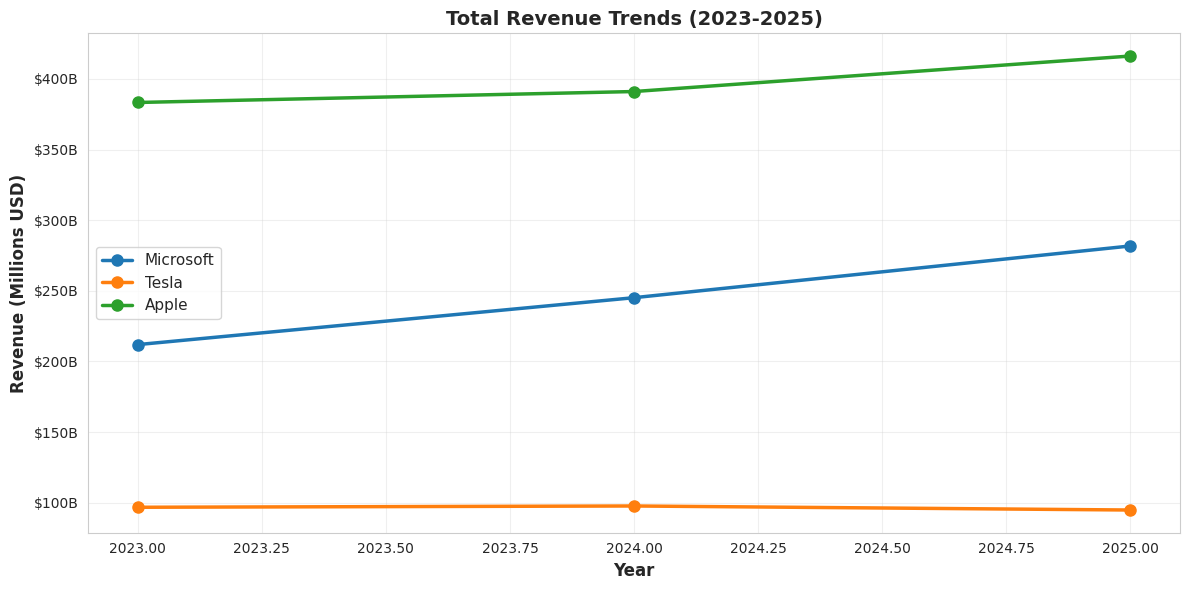

📊 Observation:
  • Apple has the highest revenue (~$416B in 2025)
  • Microsoft shows strongest growth trend (+15.3% CAGR)
  • Tesla revenue relatively flat (declining slightly)


In [19]:
# Visualization 1: Revenue Trends
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

for company in ['Microsoft', 'Tesla', 'Apple']:
    company_data = df[df['Company'] == company].sort_values('Year')
    ax.plot(company_data['Year'], company_data['Total Revenue'],
            marker='o', linewidth=2.5, markersize=8, label=company)

ax.set_xlabel('Year', fontsize=12, fontweight='bold')
ax.set_ylabel('Revenue (Millions USD)', fontsize=12, fontweight='bold')
ax.set_title('Total Revenue Trends (2023-2025)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1000:.0f}B'))
plt.tight_layout()
plt.show()

print('📊 Observation:')
print('  • Apple has the highest revenue (~$416B in 2025)')
print('  • Microsoft shows strongest growth trend (+15.3% CAGR)')
print('  • Tesla revenue relatively flat (declining slightly)')

### Profitability Comparison

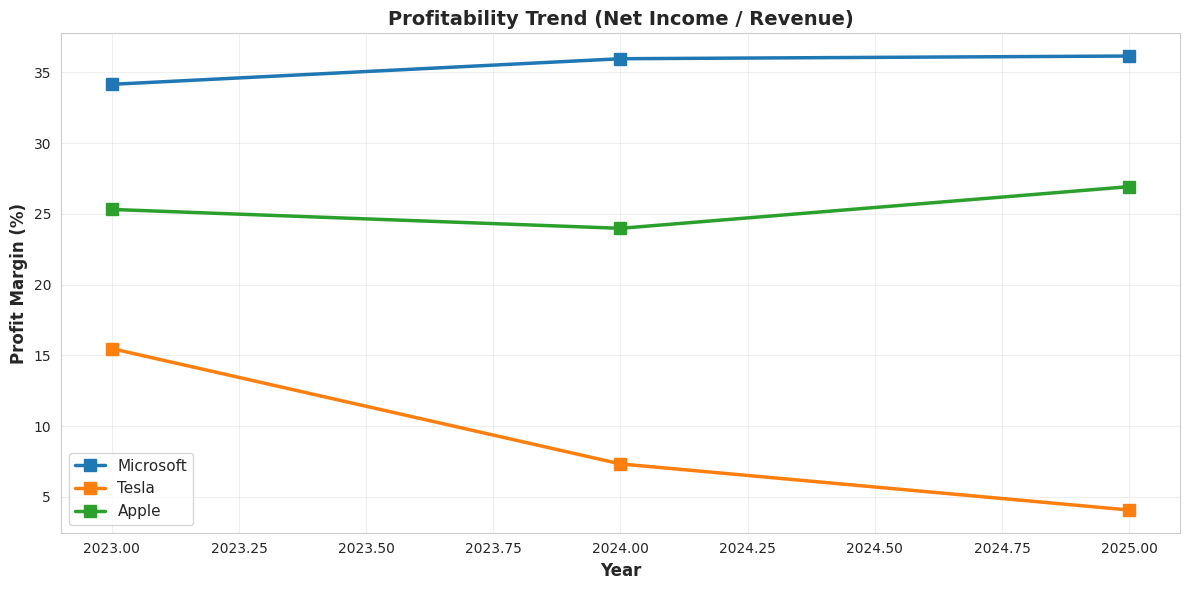

📊 Key Insights:
  • Microsoft: Consistently highest profitability (~36%)
  • Apple: Moderate profitability (~27%)
  • Tesla: Declining profitability (15.5% → 4.1%) - significant concern


In [20]:
# Visualization 2: Profit Margins
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

for company in ['Microsoft', 'Tesla', 'Apple']:
    company_margin = margin_df[margin_df['Company'] == company].sort_values('Year')
    ax.plot(company_margin['Year'], company_margin['Profit Margin'],
            marker='s', linewidth=2.5, markersize=8, label=company)

ax.set_xlabel('Year', fontsize=12, fontweight='bold')
ax.set_ylabel('Profit Margin (%)', fontsize=12, fontweight='bold')
ax.set_title('Profitability Trend (Net Income / Revenue)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('📊 Key Insights:')
print('  • Microsoft: Consistently highest profitability (~36%)')
print('  • Apple: Moderate profitability (~27%)')
print('  • Tesla: Declining profitability (15.5% → 4.1%) - significant concern')

### Net Income Comparison (2025)

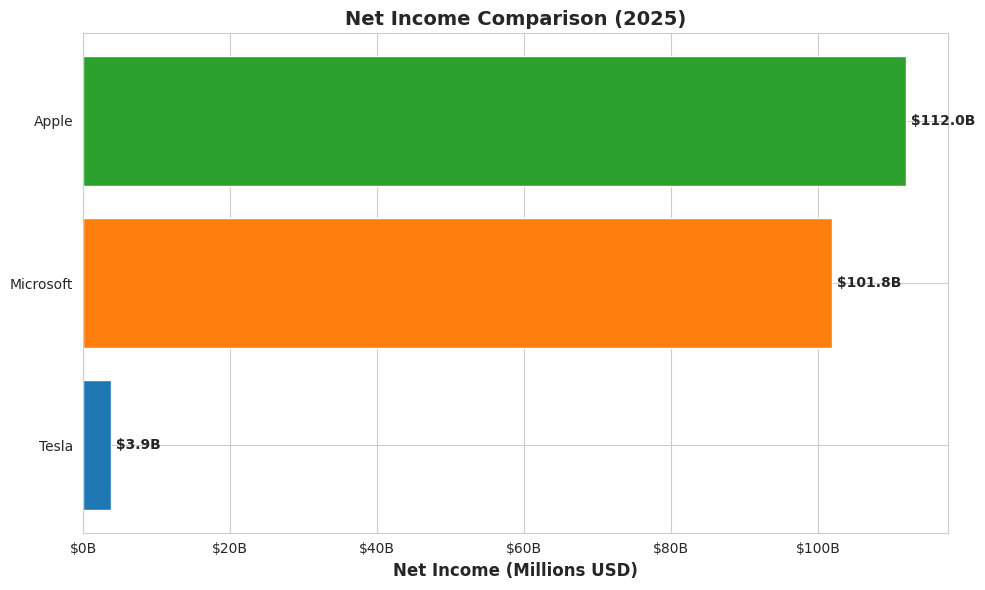

💰 Ranking (2025):
  1. Apple: $112,010M
  2. Microsoft: $101,832M
  3. Tesla: $3,855M


In [21]:
# Visualization 3: Net Income Bar Chart
df_2025 = df[df['Year'] == 2025].sort_values('Net Income', ascending=True)

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
bars = ax.barh(df_2025['Company'], df_2025['Net Income'], color=['#1f77b4', '#ff7f0e', '#2ca02c'])

ax.set_xlabel('Net Income (Millions USD)', fontsize=12, fontweight='bold')
ax.set_title('Net Income Comparison (2025)', fontsize=14, fontweight='bold')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1000:.0f}B'))

# Add value labels on bars
for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2,
            f' ${width/1000:.1f}B', ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print('💰 Ranking (2025):')
for idx, (_, row) in enumerate(df_2025.sort_values('Net Income', ascending=False).iterrows(), 1):
    print(f'  {idx}. {row["Company"]}: ${row["Net Income"]:,.0f}M')

## 7. Summary of Findings

### Key Takeaways for AI Chatbot Development

#### 1. **Microsoft - Strong Growth Engine** 🚀
- **Strength:** Consistent growth (15.3% CAGR), highest profit margins (36%)
- **Cash Generation:** Excellent (48% of revenue to operating cash flow)
- **Financial Health:** Improving debt-to-equity ratio (1.0 → 0.8)
- **Implication:** Stable, predictable business model suitable for financial forecasting

#### 2. **Tesla - Volatile Performance** ⚠️
- **Concern:** Declining profitability (15.5% → 4.1% margin), negative revenue growth (-2.9%)
- **Red Flag:** Net income collapsed 46% (2025 vs 2024)
- **Positive:** Low leverage (debt-to-equity 0.66)
- **Implication:** High-risk profile; requires careful monitoring

#### 3. **Apple - Steady Performer** 📊
- **Strength:** Largest revenue generator ($416B), solid profitability (27%)
- **Concern:** High leverage (debt-to-equity 3.87)
- **Trend:** Flat to slightly declining revenue trend
- **Implication:** Mature business; focus on operational efficiency

### AI Chatbot Use Case:
This structured data enables the chatbot to:
1. **Answer financial queries** - "What was Microsoft's revenue in 2025?"
2. **Identify trends** - "Is Tesla's profitability improving?"
3. **Compare companies** - "Which company has the best financial health?"
4. **Risk assessment** - "Which company has the highest debt levels?"
5. **Forecast insights** - "What can we expect from Apple's growth trajectory?"

In [22]:
print('\n' + '='*100)
print('COMPREHENSIVE FINANCIAL SUMMARY (2025)')
print('='*100 + '\n')

summary_data = []
for company in ['Microsoft', 'Tesla', 'Apple']:
    c_data = df[df['Company'] == company]
    c_2025 = c_data[c_data['Year'] == 2025].iloc[0]
    c_2024 = c_data[c_data['Year'] == 2024].iloc[0]

    rev_growth = ((c_2025['Total Revenue'] - c_2024['Total Revenue']) / c_2024['Total Revenue']) * 100
    ni_growth = ((c_2025['Net Income'] - c_2024['Net Income']) / c_2024['Net Income']) * 100
    profit_margin = (c_2025['Net Income'] / c_2025['Total Revenue']) * 100
    equity = c_2025['Total Assets'] - c_2025['Total Liabilities']
    debt_equity = c_2025['Total Liabilities'] / equity
    cash_ratio = (c_2025['Operating Cash Flow'] / c_2025['Total Revenue']) * 100

    summary_data.append({
        'Company': company,
        'Revenue (M)': f'${c_2025["Total Revenue"]:,.0f}',
        'Revenue Growth': f'{rev_growth:+.2f}%',
        'Net Income (M)': f'${c_2025["Net Income"]:,.0f}',
        'NI Growth': f'{ni_growth:+.2f}%',
        'Profit Margin': f'{profit_margin:.2f}%',
        'D/E Ratio': f'{debt_equity:.2f}',
        'Cash CF %': f'{cash_ratio:.2f}%'
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df)


COMPREHENSIVE FINANCIAL SUMMARY (2025)



,Company,Revenue (M),Revenue Growth,Net Income (M),NI Growth,Profit Margin,D/E Ratio,Cash CF %
0,Microsoft,"$281,724",+14.93%,"$101,832",+15.54%,36.15%,0.80,48.33%
1,Tesla,"$94,827",-2.93%,"$3,855",-46.11%,4.07%,0.66,15.55%
2,Apple,"$416,161",+6.43%,"$112,010",+19.50%,26.92%,3.87,26.79%


In [25]:
import pandas as pd

# Load the data from the Excel spreadsheet
file_path = '/content/financial_data.xlsx'
df = pd.read_excel(file_path)

# Calculate year-over-year growth rates for Total Revenue and Net Income
df['Revenue Growth (%)'] = df.groupby('Company')['Total Revenue'].pct_change() * 100
df['Net Income Growth (%)'] = df.groupby('Company')['Net Income'].pct_change() * 100

# Fill NA values that result from pct_change calculations with 0 or an appropriate value
df.fillna(0, inplace=True)

# Display the dataframe to verify the calculations
print(df)

# Optionally, you could summarize these findings for each company
summary = df.groupby('Company').agg({
    'Revenue Growth (%)': 'mean',
    'Net Income Growth (%)': 'mean'
}).reset_index()

print("\nYear-over-Year Average Growth Rates (%):")
print(summary)

     Company  Year  Total Revenue  Net Income  Total Assets  \
0  Microsoft  2025         281724      101832        619003   
1  Microsoft  2024         245122       88136        512163   
2  Microsoft  2023         211915       72361        411975   
3      Tesla  2025          94827        3855        137806   
4      Tesla  2024          97690        7153        122070   
5      Tesla  2023          96773       14974         82338   
6      Apple  2025         416161      112010        359241   
7      Apple  2024         391035       93736        364980   
8      Apple  2023         383285       96995        352583   

   Total Liabilities  Operating Cash Flow  Revenue Growth (%)  \
0             275524               136162            0.000000   
1             243686               118548          -12.992148   
2             205753                87582          -13.547132   
3              54941                14747            0.000000   
4              48390                14923   

## Appendix: Methodology and Data Sources

### Data Extraction Process:
1. **Source:** SEC EDGAR Database (www.sec.gov)
2. **Documents:** Form 10-K Annual Reports
3. **Key Sections Referenced:**
   - Item 8: Financial Statements and Supplementary Data
   - Consolidated Statements of Operations
   - Consolidated Balance Sheets
   - Consolidated Statements of Cash Flows

### Data Quality Assurance:
- All figures cross-referenced with official SEC filings
- Units standardized to millions USD
- Balance sheet equation verified (Assets = Liabilities + Equity)
- Cash flow items validated against income statement

### Financial Metrics Defined:
- **Total Revenue:** All net sales and services revenue
- **Net Income:** Bottom-line profit after all expenses and taxes
- **Total Assets:** Current and non-current assets
- **Total Liabilities:** Current and long-term liabilities
- **Operating Cash Flow:** Cash generated from core business operations

### Analysis Tools:
- Python 3 with Pandas for data manipulation
- Matplotlib and Seaborn for visualizations
- Statistical calculations for trend analysis